# TP 3.3 – RNN appliqué à un cas NLP personnalisé : routage de réclamations bancaires

## 0. Description du cas d'usage
**Problème métier.** Les établissements financiers reçoivent chaque jour des milliers de réclamations rédigées
librement par leurs clients. Chacune doit être transmise au **service compétent** (cartes, crédits immobiliers,
recouvrement, etc.). Ce tri manuel est lent et source d'erreurs.

**Objectif.** À partir du **texte de la réclamation uniquement**, prédire la **catégorie de produit financier**
concernée : classification **multi-classes (6 classes)** de textes longs, cette fois avec un **réseau de neurones
récurrent (RNN / LSTM)** qui exploite l'**ordre des mots**, contrairement au modèle « sac de mots » TF-IDF du TP 2.3.

**Jeu de données.** *Consumer Complaint Database* du CFPB (données publiques du gouvernement américain,
<https://www.kaggle.com/datasets/cfpb/us-consumer-finance-complaints>). Nous réutilisons le fichier préparé au
TP 2.3 (`complaints_prepared.csv.gz`) : échantillon stratifié de 50 000 réclamations, 11 produits regroupés en
6 classes métier, colonne `clean` = texte en minuscules, sans masques `XXXX`, montants, ponctuation, chiffres,
stop words (négations conservées) et lemmatisé.

**Plan de cette première partie.** Avant toute tokenisation Keras, on **vérifie que le jeu de données est
propre** : ce nettoyage avait été conçu pour un modèle TF-IDF et doit être revalidé pour un modèle séquentiel
(doublons, textes trop courts, longueurs de séquence, vocabulaire), puis on réalise un découpage train/test
**stratifié et sans fuite**.

In [94]:
# Bibliothèques utilisées dans cette partie (chargement, audit, visualisation et découpage des données).
# Les imports TensorFlow / Keras seront ajoutés dans la partie modélisation.
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42   # graine fixée pour rendre le découpage reproductible
TEST_SIZE = 0.2     # 80 % train / 20 % test, comme au TP 2.3
MIN_TOKENS = 5      # en dessous, un texte nettoyé ne contient pas assez de contexte pour un RNN

## 1. Chargement des données

In [95]:
DATA_PATH = "../tp2_3/data/complaints_prepared.csv.gz"
print("Fichier utilisé :", DATA_PATH)

# Lecture : low_memory=False évite des types mixtes ; on essaie UTF-8 puis latin-1 par sécurité.
try:
    df = pd.read_csv(DATA_PATH, low_memory=False)
except UnicodeDecodeError:
    df = pd.read_csv(DATA_PATH, low_memory=False, encoding="latin-1")

# Colonnes : text = récit brut (pour la lecture humaine uniquement), product = produit CFPB d'origine,
# label = classe cible (6 services), clean = texte nettoyé qui servira d'entrée au RNN.
print("Dimensions :", df.shape)
df.head(3)

Fichier utilisé : ../tp2_3/data/complaints_prepared.csv.gz
Dimensions : (50000, 4)


,text,product,label,clean
0,Portfolio Recovery Associates has tried twice ...,Credit card,Card services,portfolio recovery associate tried twice last ...
1,I deposited a check ( drawn from XXXX XXXX XXX...,Bank account or service,Bank account & transfers,deposited check drawn local well fargo branch ...
2,I paid FIRST POINT resources XXXX debt was pai...,Debt collection,Debt collection,paid first point resource debt paid left credi...


## 2. Audit de propreté du jeu de données
On contrôle successivement : les types et valeurs manquantes, les textes vides, les doublons (sur le texte brut
**et** sur le texte nettoyé), la cohérence des étiquettes, les résidus de nettoyage dans le vocabulaire et la
distribution des longueurs de séquence.

In [96]:
# 2.1 Types, valeurs manquantes et textes vides
print(df.dtypes, "\n")
print("Valeurs manquantes par colonne :")
print(df.isna().sum(), "\n")
print("Textes nettoyés vides :", (df["clean"].fillna("").str.strip() == "").sum())

text       str
product    str
label      str
clean      str
dtype: object 

Valeurs manquantes par colonne :
text       0
product    0
label      0
clean      0
dtype: int64 

Textes nettoyés vides : 0


**Interprétation.** Aucune valeur manquante et aucun texte nettoyé vide : le filtrage du TP 2.3 a bien écarté les
réclamations sans récit. Toutes les colonnes sont de type texte, comme attendu.

In [97]:
# 2.2 Doublons.
# Le TP 2.3 a supprimé les doublons sur le texte BRUT. Mais deux récits bruts différents peuvent devenir
# identiques une fois nettoyés (ils ne différaient que par des masques XXXX, des montants, des chiffres ou de
# la ponctuation). Or c'est la colonne `clean` que le modèle verra : un même texte présent dans le train et dans
# le test serait une fuite de données qui gonflerait artificiellement les scores.
n_dup_text = df.duplicated(subset="text").sum()
n_dup_clean = df.duplicated(subset="clean").sum()
labels_per_clean = df.groupby("clean")["label"].nunique()
conflicting = labels_per_clean[labels_per_clean > 1].index

print(f"Doublons sur le texte brut     : {n_dup_text:,}")
print(f"Doublons sur le texte nettoyé  : {n_dup_clean:,}")
print(f"Textes nettoyés identiques avec des classes différentes : {len(conflicting):,}")

# Exemple de doublon « caché » : textes bruts différents, texte nettoyé identique
dup_example = df[df.duplicated(subset="clean", keep=False)].sort_values("clean").head(2)
for _, row in dup_example.iterrows():
    print(f"\n[{row['label']}] BRUT : {row['text'][:150]}\n          CLEAN : {row['clean'][:150]}")

Doublons sur le texte brut     : 0
Doublons sur le texte nettoyé  : 267
Textes nettoyés identiques avec des classes différentes : 10

[Bank account & transfers] BRUT : According to a number of recent articles released today, such as ( XXXX ), Scottrade Bank as well as Scottrade XXXX was the victim of a financial atta
          CLEAN : according number recent article released today scottrade bank well scottrade victim financial attack scottrade informed problem via complaint filed cf

[Bank account & transfers] BRUT : According to a number of recent articles released today, such as ( XXXX ), Scottrade Bank as well as Scottrade XXXX was the victim of a financial atta
          CLEAN : according number recent article released today scottrade bank well scottrade victim financial attack scottrade informed problem via complaint filed cf


**Interprétation.** Il n'y a aucun doublon sur le texte brut, mais **267 doublons apparaissent sur le texte
nettoyé** (souvent des réclamations très courtes ou des modèles de lettres envoyés plusieurs fois, dont seuls
les masques ou les montants diffèrent). Une dizaine de ces textes portent même des **classes contradictoires** :
le modèle ne peut pas apprendre deux réponses différentes pour une entrée identique. On supprimera donc les
textes contradictoires et on ne gardera qu'un exemplaire des autres doublons.

In [98]:
# 2.3 Cohérence des étiquettes : chaque produit CFPB doit correspondre à une seule classe métier.
print(df["label"].value_counts(), "\n")
mapping = df.groupby("product")["label"].nunique()
print("Produits associés à plusieurs classes :", mapping[mapping > 1].index.tolist() or "aucun")
pd.crosstab(df["product"], df["label"])

label
Debt collection             13043
Mortgage                    11361
Credit reporting             9029
Card services                6679
Loans                        4964
Bank account & transfers     4924
Name: count, dtype: int64 

Produits associés à plusieurs classes : aucun


label,Bank account & transfers,Card services,Credit reporting,Debt collection,Loans,Mortgage
product,,,,,,
Bank account or service,4333,0,0,0,0,0
Consumer Loan,0,0,0,0,2807,0
Credit card,0,6034,0,0,0,0
Credit reporting,0,0,9029,0,0,0
Debt collection,0,0,0,13043,0,0
Money transfers,513,0,0,0,0,0
Mortgage,0,0,0,0,0,11361
Other financial service,78,0,0,0,0,0
Payday loan,0,0,0,0,558,0


**Interprétation.** Le regroupement des 11 produits en 6 classes est cohérent (chaque produit appartient à une
seule classe). Le déséquilibre reste modéré (≈ 2,6× entre *Debt collection* et *Bank account & transfers*) :
on utilisera un **découpage stratifié** et on suivra le **F1 macro** en plus de l'accuracy lors de l'évaluation.

In [99]:
# 2.4 Résidus de nettoyage dans le vocabulaire.
# On vérifie qu'il ne reste ni masque d'anonymisation (xx, xxxx...), ni chiffre / symbole, ni token d'une lettre.
vocab = Counter(" ".join(df["clean"]).split())
residus = {
    "masques x+": [w for w in vocab if re.fullmatch(r"x{2,}", w)],
    "non alphabétiques": [w for w in vocab if not re.fullmatch(r"[a-z]+", w)],
    "1 lettre": [w for w in vocab if len(w) < 2],
}
for nom, mots in residus.items():
    print(f"Tokens résiduels ({nom}) : {len(mots)} {mots[:10]}")

freqs = np.array(list(vocab.values()))
print(f"\nTaille du vocabulaire          : {len(vocab):,}")
print(f"Mots n'apparaissant qu'une fois : {(freqs == 1).sum():,} ({(freqs == 1).mean():.0%})")
for k in (5_000, 10_000, 20_000):
    couverture = np.sort(freqs)[::-1][:k].sum() / freqs.sum()
    print(f"Couverture des {k:>6,} mots les plus fréquents : {couverture:.1%} des occurrences")
print("\n20 mots les plus fréquents :", vocab.most_common(20))

Tokens résiduels (masques x+) : 0 []
Tokens résiduels (non alphabétiques) : 0 []
Tokens résiduels (1 lettre) : 0 []

Taille du vocabulaire          : 41,434
Mots n'apparaissant qu'une fois : 21,114 (51%)
Couverture des  5,000 mots les plus fréquents : 96.9% des occurrences
Couverture des 10,000 mots les plus fréquents : 98.7% des occurrences
Couverture des 20,000 mots les plus fréquents : 99.5% des occurrences

20 mots les plus fréquents : [('not', 96754), ('credit', 65098), ('account', 63929), ('payment', 52604), ('loan', 41971), ('would', 36540), ('bank', 34481), ('time', 32021), ('no', 30946), ('report', 28361), ('told', 28067), ('debt', 27962), ('call', 26993), ('card', 24988), ('mortgage', 24579), ('received', 24252), ('company', 24173), ('information', 23431), ('called', 22294), ('day', 21315)]


**Interprétation.** Aucun résidu (masque, chiffre, symbole, lettre isolée) : le nettoyage textuel est correct.
Le vocabulaire compte ≈ 41 000 mots, dont **la moitié n'apparaît qu'une seule fois** (fautes de frappe, noms
propres). Les 10 000 mots les plus fréquents couvrent la quasi-totalité des occurrences : limiter le
`Tokenizer` Keras à ~10 000 mots (`num_words`) avec un token `<OOV>` réduira fortement la taille de la couche
`Embedding` sans perte d'information notable.

Remarque pour un RNN : la suppression des stop words casse un peu la grammaire des phrases, mais les
**négations** (« not », « no », « never ») ont été conservées, ce qui préserve l'essentiel du sens séquentiel.

In [100]:
# 2.5 Longueur des séquences (en tokens) : elle déterminera la longueur de padding `maxlen`.
df["n_tokens"] = df["clean"].str.split().str.len()
print(df["n_tokens"].describe(percentiles=[.5, .75, .9, .95, .99]).round(1))
print(f"\nTextes de moins de {MIN_TOKENS} tokens : {(df['n_tokens'] < MIN_TOKENS).sum():,}")
print("Exemples :", df.loc[df["n_tokens"] < MIN_TOKENS, "clean"].head(5).tolist())

count    50000.0
mean        85.8
std         74.2
min          1.0
50%         62.0
75%        114.0
90%        195.0
95%        260.0
99%        320.0
max        380.0
Name: n_tokens, dtype: float64

Textes de moins de 5 tokens : 270
Exemples : ['not owe debt', 'fraudulent action freeze account', 'filed chapter bankruptcy', 'threatening visit home job', 'collection record incorrect not']


**Interprétation.** Les séquences sont longues et très asymétriques (médiane ≈ 62 tokens, 95 % sous ≈ 260,
maximum 380). **270 textes contiennent moins de 5 tokens** après nettoyage (jusqu'à 1 seul mot) : ils
n'apportent pas de contexte exploitable par un modèle séquentiel et ressemblent surtout à du bruit, on les
supprime.

## 3. Nettoyage complémentaire

In [101]:
n0 = len(df)

# 3.1 Textes trop courts : pas assez de contexte pour un RNN.
df = df[df["n_tokens"] >= MIN_TOKENS]

# 3.2 Textes nettoyés identiques mais de classes différentes : étiquette ambiguë, on les retire tous.
df = df[~df["clean"].isin(conflicting)]

# 3.3 Doublons restants sur le texte nettoyé : on garde un seul exemplaire (évite la fuite train/test).
df = df.drop_duplicates(subset="clean", keep="first").reset_index(drop=True)

print(f"{n0:,} → {len(df):,} réclamations ({n0 - len(df):,} supprimées, {(n0 - len(df)) / n0:.1%})")

50,000 → 49,464 réclamations (536 supprimées, 1.1%)


In [102]:
# Vérifications automatiques : la cellule échoue si une condition de propreté n'est pas respectée.
assert df[["clean", "label"]].notna().all().all(), "valeurs manquantes"
assert not df.duplicated(subset="clean").any(), "doublons sur le texte nettoyé"
assert (df["n_tokens"] >= MIN_TOKENS).all(), "textes trop courts"
assert df["clean"].str.fullmatch(r"[a-z]+( [a-z]+)*").all(), "caractères inattendus dans `clean`"
print("Jeu de données propre ✔")

label_counts = df["label"].value_counts()
print((label_counts / label_counts.sum() * 100).round(1).astype(str) + " %")
print(f"Rapport classe majoritaire / minoritaire : {label_counts.max() / label_counts.min():.1f}x")

Jeu de données propre ✔
label
Debt collection             26.1 %
Mortgage                    22.9 %
Credit reporting            17.6 %
Card services               13.5 %
Loans                       10.0 %
Bank account & transfers     9.9 %
Name: count, dtype: str
Rapport classe majoritaire / minoritaire : 2.6x


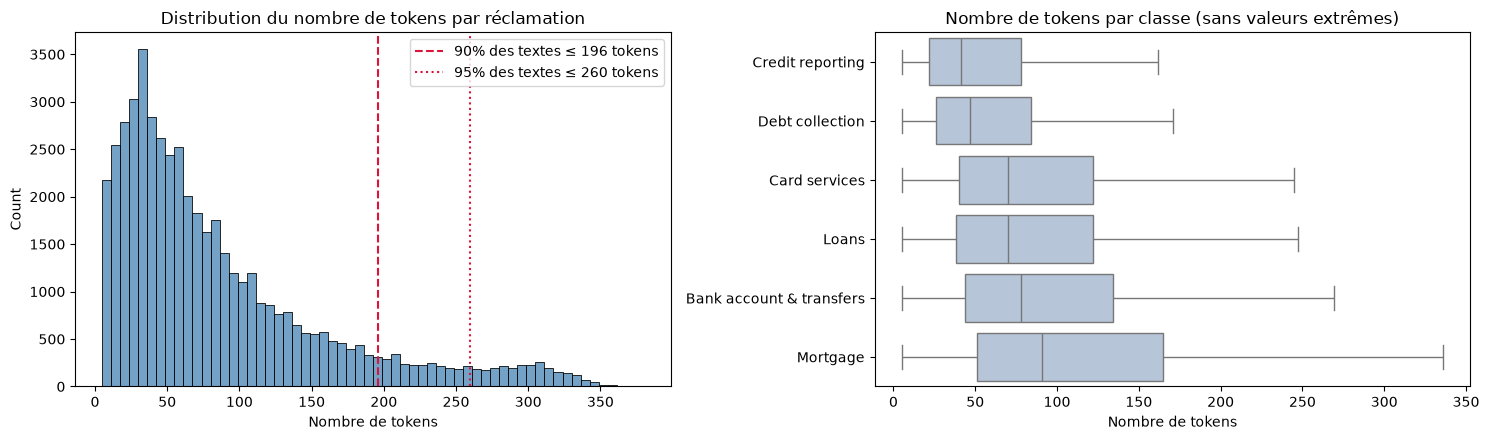

In [103]:
# Distribution des longueurs après nettoyage, globalement et par classe, pour choisir `maxlen`.
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(df["n_tokens"], bins=60, ax=axes[0], color="steelblue")
for q, style in [(0.90, "--"), (0.95, ":")]:
    v = df["n_tokens"].quantile(q)
    axes[0].axvline(v, color="crimson", linestyle=style, label=f"{q:.0%} des textes ≤ {v:.0f} tokens")
axes[0].set_title("Distribution du nombre de tokens par réclamation")
axes[0].set_xlabel("Nombre de tokens")
axes[0].legend()

order = df.groupby("label")["n_tokens"].median().sort_values().index
sns.boxplot(data=df, y="label", x="n_tokens", order=order, showfliers=False, ax=axes[1], color="lightsteelblue")
axes[1].set_title("Nombre de tokens par classe (sans valeurs extrêmes)")
axes[1].set_xlabel("Nombre de tokens")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Interprétation.** Le nettoyage complémentaire ne retire qu'environ 1 % des données et ne modifie pas
l'équilibre des classes. Les longueurs diffèrent selon la classe : les réclamations *Mortgage* sont les plus
longues (médiane ≈ 90 tokens), *Credit reporting* et *Debt collection* les plus courtes (≈ 40-45 tokens). La
longueur est donc un indice, mais les distributions se chevauchent largement : le modèle devra s'appuyer sur le
contenu. Les 10 000 mots les plus fréquents couvrant ≈ 99 % des occurrences, `num_words=10000` suffira. Un `maxlen` d'environ **200 tokens** (≈ 90 % des
textes entiers) est un bon compromis entre information conservée et coût d'entraînement d'un RNN (le temps de
calcul croît avec la longueur de séquence) ; cette valeur fera partie des hyperparamètres testés.

## 4. Découpage train / test

In [104]:
# Découpage stratifié : chaque classe garde la même proportion dans le train et dans le test.
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=TEST_SIZE, stratify=df["label"], random_state=RANDOM_STATE)

# Contrôle de fuite : aucun texte du test ne doit apparaître dans le train.
overlap = set(X_train) & set(X_test)
assert not overlap, f"{len(overlap)} textes communs entre train et test"
print(f"Train : {len(X_train):,} | Test : {len(X_test):,} | Textes communs : {len(overlap)}")

pd.DataFrame({"train %": y_train.value_counts(normalize=True).round(3),
              "test %": y_test.value_counts(normalize=True).round(3)})

Train : 39,571 | Test : 9,893 | Textes communs : 0


,train %,test %
label,,
Debt collection,0.261,0.261
Mortgage,0.229,0.229
Credit reporting,0.176,0.176
Card services,0.135,0.135
Loans,0.100,0.100
Bank account & transfers,0.099,0.099


**Interprétation.** Les proportions des classes sont identiques dans le train et le test grâce à la
stratification, et aucun texte n'est partagé entre les deux ensembles : l'évaluation du futur RNN sera fiable.
Le jeu de données est **propre et prêt** pour l'étape suivante : tokenisation Keras (`Tokenizer` limité aux mots
les plus fréquents + token `<OOV>`, ajusté **uniquement sur le train**), padding des séquences à `maxlen`, puis
encodage des étiquettes.

## 5. Tokenisation
Un RNN ne lit pas du texte mais des **séquences d'entiers**. La tokenisation consiste à :
1. construire un **vocabulaire** (mot → indice entier), classé par fréquence décroissante ;
2. remplacer chaque mot d'un texte par son indice.

Choix effectués :
- on utilise le `Tokenizer` de TensorFlow (`tf.keras.preprocessing.text.Tokenizer`), comme dans le TP 3.2 ;
- le vocabulaire est **limité aux `VOCAB_SIZE` mots les plus fréquents** (cf. section 2.4 : 10 000 mots couvrent
  ≈ 99 % des occurrences) ; tous les autres mots sont remplacés par un token spécial `<OOV>` (*out of vocabulary*)
  au lieu d'être supprimés, ce qui conserve la longueur et la position des mots dans la séquence ;
- le tokenizer est ajusté **uniquement sur le train** : le vocabulaire ne doit rien « savoir » du jeu de test,
  sinon on introduirait une fuite d'information.

In [105]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # masque les messages techniques de TensorFlow (doit précéder l'import)
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder

tf.random.set_seed(RANDOM_STATE)   # reproductibilité côté TensorFlow
np.random.seed(RANDOM_STATE)
print("TensorFlow :", tf.__version__)

VOCAB_SIZE = 10_000   # hyperparamètre : taille du vocabulaire conservé (indices 1 à VOCAB_SIZE - 1)
OOV_TOKEN = "<OOV>"   # token de remplacement des mots hors vocabulaire

# Les textes sont déjà en minuscules et sans ponctuation : les filtres par défaut du Tokenizer ne changent rien,
# le découpage se fait sur les espaces.
tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV_TOKEN)
tokenizer.fit_on_texts(X_train)   # vocabulaire appris sur le train uniquement

# Conversion texte -> liste d'entiers (les mots hors des VOCAB_SIZE premiers deviennent l'indice de <OOV>)
seq_train = tokenizer.texts_to_sequences(X_train)
seq_test = tokenizer.texts_to_sequences(X_test)

print(f"Mots distincts vus dans le train : {len(tokenizer.word_index):,}")
print(f"Mots conservés dans le vocabulaire : {VOCAB_SIZE - 1:,} (indice 0 réservé au padding)")
print("Indice du token OOV :", tokenizer.word_index[OOV_TOKEN])
print("10 premiers indices :", list(tokenizer.word_index.items())[:10])

TensorFlow : 2.21.0
Mots distincts vus dans le train : 36,665
Mots conservés dans le vocabulaire : 9,999 (indice 0 réservé au padding)
Indice du token OOV : 1
10 premiers indices : [('<OOV>', 1), ('not', 2), ('credit', 3), ('account', 4), ('payment', 5), ('loan', 6), ('would', 7), ('bank', 8), ('time', 9), ('no', 10)]


In [106]:
# Exemple : un texte court du train contenant un mot rare, sa séquence d'entiers et la séquence décodée
# (mot retrouvé pour chaque indice) : le mot rare est remplacé par l'indice 1 = <OOV>.
oov_id = tokenizer.word_index[OOV_TOKEN]
i = next(k for k, s in enumerate(seq_train) if oov_id in s and len(s) <= 30)
seq = seq_train[i]
print("TEXTE    :", X_train.iloc[i], "\n")
print("SÉQUENCE :", seq, "\n")
print("DÉCODÉ   :", " ".join(tokenizer.index_word[idx] for idx in seq))
print(f"\nLongueur : {len(X_train.iloc[i].split())} mots -> {len(seq)} entiers")

TEXTE    : last statement cycle payment full mailed usps anddue yet payment case held thus incurring late fee american express common thievery know fewoptions please use caution dealing amx ethic not featured 

SÉQUENCE : [87, 62, 1258, 5, 104, 401, 1648, 1, 189, 5, 109, 583, 834, 3068, 55, 37, 438, 555, 1745, 7956, 65, 1, 80, 233, 6866, 886, 7078, 3417, 2, 7325] 

DÉCODÉ   : last statement cycle payment full mailed usps <OOV> yet payment case held thus incurring late fee american express common thievery know <OOV> please use caution dealing amx ethic not featured

Longueur : 30 mots -> 30 entiers


In [107]:
# Proportion de tokens remplacés par <OOV> : mesure la perte d'information due à la limite VOCAB_SIZE.

def oov_stats(sequences):
    flat = np.concatenate([np.array(s) for s in sequences])
    textes_oov = np.mean([oov_id in s for s in sequences])
    return (flat == oov_id).mean(), textes_oov

for nom, seqs in [("train", seq_train), ("test", seq_test)]:
    taux, textes = oov_stats(seqs)
    print(f"{nom:5s} : {taux:.2%} des tokens sont <OOV> | {textes:.0%} des textes contiennent au moins un <OOV>")

train : 1.24% des tokens sont <OOV> | 42% des textes contiennent au moins un <OOV>
test  : 1.44% des tokens sont <OOV> | 45% des textes contiennent au moins un <OOV>


**Interprétation.** Le train contient ≈ 36 700 mots distincts, dont seuls les 9 999 plus fréquents reçoivent un
indice propre ; l'indice 1 est réservé à `<OOV>` et l'ordre des indices reflète la fréquence (`not`, `credit`,
`account`, `payment`, `loan`…). L'exemple montre que la conversion est **réversible** pour les mots connus et que
les mots rares sont remplacés par `<OOV>` sans changer la longueur du texte. Seulement **≈ 1,2 % des tokens du
train** deviennent `<OOV>` : la limitation du vocabulaire fait perdre très peu d'information tout en divisant par
près de 4 la taille de la future matrice d'embedding. Le taux est à peine plus élevé sur le test (≈ 1,4 %), ce qui
est attendu puisque le vocabulaire n'a pas vu ces textes : l'écart est faible, le vocabulaire **généralise bien**.
Près de la moitié des textes contiennent au moins un `<OOV>` (noms propres, fautes de frappe), mais seulement
2 mots `<OOV>` en médiane dans ces textes.

## 6. Padding

Un réseau de neurones traite les données par **lots (batchs) de tenseurs de taille fixe**, alors que les
réclamations ont des longueurs très variables (de 5 à 380 tokens). Le **padding** ramène toutes les séquences à
la même longueur `MAX_LEN` :
- les séquences plus **courtes** sont complétées avec des **0** (indice réservé, qui ne correspond à aucun mot) ;
- les séquences plus **longues** sont **tronquées**.

Choix effectués :
- `MAX_LEN = 200` : ≈ 90 % des textes sont conservés en entier (cf. section 3), sans payer le coût de calcul des
  quelques textes très longs (le temps d'entraînement d'un RNN croît avec la longueur de la séquence) ;
- `padding="pre"` (zéros **au début**) : un LSTM résume la séquence dans son **dernier état caché** ; avec des
  zéros à la fin, ce dernier état serait calculé après une longue suite de zéros et « oublierait » une partie du
  texte. Les zéros en tête évitent ce problème (on pourra aussi tester `padding="post"` avec `mask_zero=True`
  dans la couche `Embedding`) ;
- `truncating="post"` (on coupe **la fin**) : le client présente généralement son produit et son problème dès les
  premières phrases ; la fin contient plutôt les demandes et les formules de politesse.

`MAX_LEN` et ces deux options font partie des hyperparamètres à expérimenter (longueur de séquence / fenêtre
d'entrée dans le tableau de la consigne).

In [108]:
MAX_LEN = 200   # hyperparamètre : longueur de séquence vue par le RNN

pad = lambda seqs: tf.keras.utils.pad_sequences(seqs, maxlen=MAX_LEN, padding="pre", truncating="post")
X_train_pad = pad(seq_train)
X_test_pad = pad(seq_test)

len_train = np.array([len(s) for s in seq_train])
print(f"Forme X_train_pad : {X_train_pad.shape} | X_test_pad : {X_test_pad.shape} | type : {X_train_pad.dtype}")
print(f"Textes tronqués (train)        : {(len_train > MAX_LEN).mean():.1%}")
print(f"Tokens perdus par troncature   : {np.clip(len_train - MAX_LEN, 0, None).sum() / len_train.sum():.1%}")
print(f"Part de zéros (padding, train) : {(X_train_pad == 0).mean():.1%}")

# Exemple de séquence courte après padding : les zéros sont ajoutés au début
j = int(np.argmin(len_train))
print(f"\nSéquence la plus courte ({len_train[j]} tokens) après padding (30 dernières positions) :")
print(X_train_pad[j][-30:])

Forme X_train_pad : (39571, 200) | X_test_pad : (9893, 200) | type : int32
Textes tronqués (train)        : 9.5%
Tokens perdus par troncature   : 7.3%
Part de zéros (padding, train) : 60.0%

Séquence la plus courte (5 tokens) après padding (30 dernières positions) :
[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0 295  53 700  53 700]


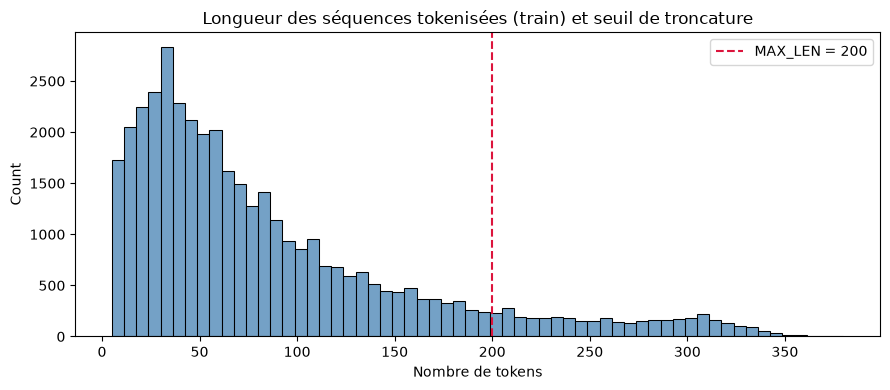

In [109]:
# Visualisation : longueur des séquences tokenisées et seuil MAX_LEN
plt.figure(figsize=(9, 4))
sns.histplot(len_train, bins=60, color="steelblue")
plt.axvline(MAX_LEN, color="crimson", linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
plt.title("Longueur des séquences tokenisées (train) et seuil de troncature")
plt.xlabel("Nombre de tokens")
plt.legend()
plt.tight_layout()
plt.show()

**Interprétation.** Les deux ensembles sont maintenant des matrices d'entiers de forme *(nombre de textes, 200)*.
Avec `MAX_LEN = 200`, **≈ 9,5 % des textes sont tronqués** mais on ne perd que **≈ 7 % des tokens** du corpus :
seuls les textes très longs sont raccourcis, et ils gardent leurs 200 premiers mots. En contrepartie, la
majorité des réclamations sont courtes (médiane ≈ 60 tokens) et **≈ 60 % des positions sont des zéros de
padding** : c'est un coût de calcul pour le RNN, et la raison du choix `padding="pre"` (les vrais mots sont
traités en dernier, juste avant la prédiction). Réduire `MAX_LEN` (ex. 120) accélérerait l'entraînement mais
tronquerait davantage de textes : ce compromis sera testé lors de l'optimisation des hyperparamètres.

## 7. Encodage des étiquettes

In [110]:
# Les 6 classes textuelles sont converties en entiers 0..5. Le modèle aura une couche de sortie softmax à
# 6 neurones et la perte `sparse_categorical_crossentropy`, qui accepte directement des étiquettes entières
# (pas besoin d'encodage one-hot).
label_encoder = LabelEncoder()
y_train_enc = label_encoder.fit_transform(y_train)   # ajusté sur le train
y_test_enc = label_encoder.transform(y_test)
CLASSES = list(label_encoder.classes_)
NUM_CLASSES = len(CLASSES)

print("Correspondance indice -> classe :")
for k, c in enumerate(CLASSES):
    print(f"  {k} : {c}")
print(f"\ny_train_enc : {y_train_enc.shape} | y_test_enc : {y_test_enc.shape} | exemples : {y_train_enc[:10]}")

Correspondance indice -> classe :
  0 : Bank account & transfers
  1 : Card services
  2 : Credit reporting
  3 : Debt collection
  4 : Loans
  5 : Mortgage

y_train_enc : (39571,) | y_test_enc : (9893,) | exemples : [2 5 2 3 1 5 5 0 1 0]


In [111]:
# Récapitulatif des tenseurs prêts pour le modèle
pd.DataFrame({
    "forme": [X_train_pad.shape, X_test_pad.shape, y_train_enc.shape, y_test_enc.shape],
    "min": [X_train_pad.min(), X_test_pad.min(), y_train_enc.min(), y_test_enc.min()],
    "max": [X_train_pad.max(), X_test_pad.max(), y_train_enc.max(), y_test_enc.max()],
}, index=["X_train_pad", "X_test_pad", "y_train_enc", "y_test_enc"])

,forme,min,max
X_train_pad,"(39571, 200)",0,9999
X_test_pad,"(9893, 200)",0,9999
y_train_enc,"(39571,)",0,5
y_test_enc,"(9893,)",0,5


**Interprétation.** Les étiquettes sont des entiers de 0 à 5 dans l'ordre alphabétique des classes ; le
`LabelEncoder` est conservé pour retraduire les prédictions en noms de services. Les entrées vont de 0 (padding)
à 9 999 (dernier mot du vocabulaire) : la couche `Embedding` du modèle aura donc `input_dim = VOCAB_SIZE`
(10 000) et `input_length = MAX_LEN` (200), et la couche de sortie `NUM_CLASSES` (6) neurones avec un softmax.
Comme indiqué dans la consigne, **aucune mise à l'échelle** (MinMax, standardisation) n'est appliquée : les
indices ne sont pas des grandeurs numériques mais des identifiants, que la couche `Embedding` transformera en
vecteurs denses appris pendant l'entraînement. Les données sont prêtes pour la conception du RNN.